# 04_Price_Optimization: Bộ đề xuất mức giảm giá

**Phục vụ:** mục 3.6 (phương pháp) và 4.4–4.5 (kết quả) của báo cáo. **Đầu vào:** mô hình `lgbm_demand.txt` (notebook 03), `features.parquet` (02), `elasticity_by_category.csv` (01).

**Bài toán** cho mỗi sản phẩm × cửa hàng × ngày trong tập test:

```
d* = argmax_{d ∈ D} (d − c) × Q̂(d)        D = {1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70}
```

**Hai cách mô phỏng phản ứng giá Q̂(d)** (vì độ co giãn ngầm định của LightGBM là −1,03, chỉ bằng khoảng một nửa so với hồi quy fixed effects −1,98):

| Cách | Q̂(d) | Vai trò |
|---|---|---|
| **A. LightGBM** | Mô hình dự đoán lại cầu khi chỉ đổi discount | Cận dưới của độ nhạy giá |
| **B. Kết hợp (chính)** | Cầu nền LightGBM tại giá thực tế d₀ × (d / d₀)^E_ngành | Cận trên; E lấy từ hồi quy fixed effects |

**Ràng buộc:** giảm tối đa 30%; không đề xuất mức giảm sâu hơn mức chuỗi từng có trong train quá `EXTRAP_STEPS` bước lưới.
**Chính sách so sánh:** giá lịch sử (discount thực tế) và không giảm giá (d = 1).
**Kịch bản giá vốn:** c ∈ {0,3; 0,4; 0,5} giá niêm yết; c = 0,4 là kịch bản chính.

In [1]:
!pip install -q -U lightgbm

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb

# ---- Cấu hình ----
USE_DRIVE = True
PROJECT = "Dynamic_Pricing_Project"
RANDOM_STATE = 42
COSTS = [0.3, 0.4, 0.5]
MAIN_COST = 0.4
EXTRAP_STEPS = 1          # cho phép sâu hơn mức giảm sâu nhất từng có tối đa 1 bước (5 điểm %)
E_CLIP = (-6.0, -0.2)     # chặn độ co giãn theo ngành trong cách B
MAX_ROWS = None           # đặt một số (vd 300_000) nếu muốn chạy nhanh trên mẫu

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive") / PROJECT
    except ImportError:
        OUT_DIR = Path(PROJECT)
else:
    OUT_DIR = Path(PROJECT)
for sub in ["data", "figures", "tables"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e4df", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

pct = lambda x: f"{x:+.1%}"

Mounted at /content/drive


## 1. Nạp mô hình và dữ liệu test

In [3]:
meta = json.load(open(OUT_DIR / "data" / "feature_meta.json", encoding="utf-8"))
mmeta = json.load(open(OUT_DIR / "models" / "lgbm_demand_meta.json", encoding="utf-8"))
FEATURES, CAT_FEATURES = mmeta["features"], mmeta["cat_features"]
GRID = np.array(sorted(meta["discount_grid"], reverse=True))   # 1.00 → 0.70
model = lgb.Booster(model_file=str(OUT_DIR / "models" / "lgbm_demand.txt"))

df = pd.read_parquet(OUT_DIR / "data" / "features.parquet").sort_values(["series_id", "dt"], ignore_index=True)
df["disc_streak_prev"] = df.groupby("series_id").disc_streak.shift(1).fillna(0).astype("int16")
for c in CAT_FEATURES:  # dùng đúng tập category như lúc huấn luyện
    df[c] = pd.Categorical(df[c].astype(int), categories=mmeta["categories"][c])

# Mức giảm sâu nhất từng có trong train của mỗi chuỗi → ràng buộc vùng dữ liệu
MIN_VALID = meta.get("min_valid_discount", 0.3)
min_hist = df[(df.set == "train") & (df.discount >= MIN_VALID)].groupby("series_id").discount.min()

el = pd.read_csv(OUT_DIR / "tables" / "elasticity_by_category.csv")
E_OVERALL = json.load(open(OUT_DIR / "tables" / "eda_summary.json", encoding="utf-8"))["elasticity_overall"]["elasticity"]
# Ngành chưa kết luận → dùng độ co giãn tổng thể
el["E_used"] = np.where(el.nhom == "Chưa kết luận", E_OVERALL, el.elasticity).clip(*E_CLIP)
E_map = dict(zip(el.first_category_id, el.E_used))
grp_map = dict(zip(el.first_category_id, el.nhom))

te = df[(df.set == "test") & (df.usable == 1) & (df.discount >= MIN_VALID)].copy()  # loại giá lỗi
if MAX_ROWS and len(te) > MAX_ROWS:
    te = te.sample(MAX_ROWS, random_state=RANDOM_STATE)
te = te.reset_index(drop=True)
cat_int = te.first_category_id.astype(int)
te["E"] = cat_int.map(E_map).fillna(E_OVERALL).clip(*E_CLIP)
te["el_group"] = cat_int.map(grp_map).fillna("Chưa kết luận")
prod_sales = df[df.set == "train"].groupby("product_id", observed=True).sale_amount.sum().sort_values(ascending=False)
top_prod = set(prod_sales.index[: int(np.ceil(0.2 * len(prod_sales)))])
te["top20"] = te.product_id.isin(top_prod)
print(f"Dòng test tối ưu: {len(te):,} | chuỗi: {te.series_id.nunique():,} | độ co giãn tổng thể dùng thay: {E_OVERALL:.2f}")

Dòng test tối ưu: 602,350 | chuỗi: 49,819 | độ co giãn tổng thể dùng thay: -2.01


## 2. Mô phỏng cầu tại 7 mức giá (hai cách)

In [4]:
def apply_discount(X, d, streak_prev):
    X = X.copy()
    X["discount"] = np.float32(d)
    X["disc_streak"] = np.where(d < 0.995, streak_prev + 1, 0).astype("int16")
    return X

X = te[FEATURES]
prev = te.disc_streak_prev.values
d0 = te.discount.clip(lower=0.05).values

# Cách A: LightGBM dự đoán lại ở từng mức giá
QA = np.column_stack([model.predict(apply_discount(X, d, prev)) for d in GRID]).clip(min=0)
# Cầu nền tại giá thực tế
base = model.predict(X).clip(min=0)
# Cách B: cầu nền × (d / d0)^E theo ngành
QB = base[:, None] * (GRID[None, :] / d0[:, None]) ** te.E.values[:, None]

# Ràng buộc vùng dữ liệu: d ≥ (mức giảm sâu nhất từng có − EXTRAP_STEPS × 0,05)
floor_d = te.series_id.map(min_hist).fillna(1.0).values - 0.05 * EXTRAP_STEPS - 1e-9
ALLOWED = GRID[None, :] >= np.minimum(floor_d, 1.0)[:, None]
ALLOWED[:, 0] = True  # luôn được phép không giảm
print(f"Tỷ lệ (dòng × mức giá) được phép: {ALLOWED.mean():.1%}; dòng chỉ được giữ giá gốc: {(ALLOWED.sum(1) == 1).mean():.1%}")

Tỷ lệ (dòng × mức giá) được phép: 73.0%; dòng chỉ được giữ giá gốc: 0.0%


## 3. Tối ưu và so sánh chính sách

In [5]:
def optimise(Q, c, objective="profit"):
    val = (GRID[None, :] - c) * Q if objective == "profit" else GRID[None, :] * Q
    val = np.where(ALLOWED, val, -np.inf)
    j = val.argmax(1)
    return GRID[j], Q[np.arange(len(Q)), j]

def evaluate(Q, mode, c):
    d_opt, q_opt = optimise(Q, c)
    q_hist = base  # cầu tại giá thực tế (cả hai cách đều dùng cùng cầu nền)
    q_full = Q[:, 0]
    out = {"cách": mode, "c": c}
    for name, d, q in [("tối ưu", d_opt, q_opt), ("lịch sử", d0, q_hist), ("không giảm", np.ones(len(Q)), q_full)]:
        out[f"π {name}"] = float(((d - c) * q).sum())
        out[f"R {name}"] = float((d * q).sum())
        out[f"Q {name}"] = float(q.sum())
    out["Δπ vs lịch sử"] = out["π tối ưu"] / out["π lịch sử"] - 1
    out["ΔR vs lịch sử"] = out["R tối ưu"] / out["R lịch sử"] - 1
    out["Δπ vs không giảm"] = out["π tối ưu"] / out["π không giảm"] - 1
    out["ngày có giảm (tối ưu)"] = float((d_opt < 0.995).mean())
    out["ngày có giảm (lịch sử)"] = float((d0 < 0.995).mean())
    out["độ sâu TB khi giảm (tối ưu)"] = float((1 - d_opt[d_opt < 0.995]).mean()) if (d_opt < 0.995).any() else 0.0
    out["ở biên 30%"] = float((d_opt <= GRID.min() + 1e-9).mean())
    return out, d_opt

rows, D_OPT = [], {}
for mode, Q in [("A. LightGBM", QA), ("B. Kết hợp", QB)]:
    for c in COSTS:
        r, d_opt = evaluate(Q, mode, c)
        rows.append(r); D_OPT[(mode, c)] = d_opt
res = pd.DataFrame(rows)
res.to_csv(OUT_DIR / "tables" / "table_4_4_policy_results.csv", index=False)
show = res[["cách", "c", "Δπ vs lịch sử", "ΔR vs lịch sử", "Δπ vs không giảm", "ngày có giảm (tối ưu)",
            "ngày có giảm (lịch sử)", "độ sâu TB khi giảm (tối ưu)", "ở biên 30%"]]
show.style.format({c: "{:+.1%}" for c in ["Δπ vs lịch sử", "ΔR vs lịch sử", "Δπ vs không giảm"]} |
                  {c: "{:.1%}" for c in ["ngày có giảm (tối ưu)", "ngày có giảm (lịch sử)", "độ sâu TB khi giảm (tối ưu)", "ở biên 30%"]} |
                  {"c": "{:.1f}"})

,cách,c,Δπ vs lịch sử,ΔR vs lịch sử,Δπ vs không giảm,ngày có giảm (tối ưu),ngày có giảm (lịch sử),độ sâu TB khi giảm (tối ưu),ở biên 30%
0,A. LightGBM,0.3,+8.5%,+6.4%,+7.9%,82.3%,51.8%,8.2%,7.9%
1,A. LightGBM,0.4,+10.0%,+5.4%,+6.4%,77.0%,51.8%,7.1%,4.7%
2,A. LightGBM,0.5,+13.0%,+3.8%,+5.0%,69.0%,51.8%,5.9%,1.5%
3,B. Kết hợp,0.3,+17.0%,+18.3%,+16.9%,49.9%,51.8%,20.6%,15.2%
4,B. Kết hợp,0.4,+16.4%,+16.9%,+13.2%,49.9%,51.8%,17.2%,6.7%
5,B. Kết hợp,0.5,+17.1%,+13.3%,+9.4%,25.7%,51.8%,17.4%,3.1%


In [6]:
# Minh họa lý thuyết mục 2.2: tối đa DOANH THU với cầu co giãn mạnh dồn về mức giảm tối đa
rev_bound = {}
deepest_allowed = np.where(ALLOWED, GRID[None, :], np.inf).min(1)
multi = ALLOWED.sum(1) > 1   # chỉ xét dòng có ít nhất 2 mức giá được phép
for mode, Q in [("A. LightGBM", QA), ("B. Kết hợp", QB)]:
    d_rev, _ = optimise(Q, 0, objective="revenue")
    rev_bound[mode] = float((d_rev[multi] <= deepest_allowed[multi] + 1e-9).mean())
    print(f"{mode}: mục tiêu doanh thu chọn mức giảm sâu nhất được phép ở {rev_bound[mode]:.1%} số dòng")

A. LightGBM: mục tiêu doanh thu chọn mức giảm sâu nhất được phép ở 29.8% số dòng
B. Kết hợp: mục tiêu doanh thu chọn mức giảm sâu nhất được phép ở 71.8% số dòng


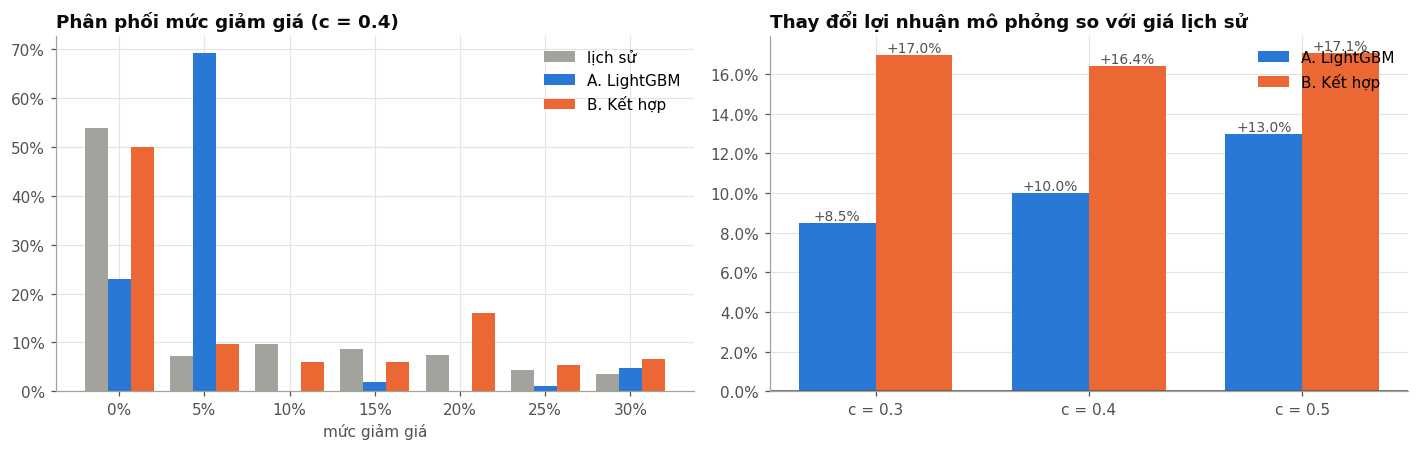

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
labels = [f"{int(round((1 - d) * 100))}%" for d in GRID]
x = np.arange(len(GRID)); w = 0.27
hist_share = [(np.isclose(np.round(d0 / 0.05) * 0.05, d)).mean() for d in GRID]
for k, (name, vals, col) in enumerate([("lịch sử", hist_share, MUTED),
                                       ("A. LightGBM", [(D_OPT[("A. LightGBM", MAIN_COST)] == d).mean() for d in GRID], C1),
                                       ("B. Kết hợp", [(D_OPT[("B. Kết hợp", MAIN_COST)] == d).mean() for d in GRID], C2)]):
    ax[0].bar(x + (k - 1) * w, vals, width=w, color=col, label=name)
ax[0].set_xticks(x, labels); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[0].set_title(f"Phân phối mức giảm giá (c = {MAIN_COST})"); ax[0].set_xlabel("mức giảm giá"); ax[0].legend()

xc = np.arange(len(COSTS))
for k, (mode, col) in enumerate([("A. LightGBM", C1), ("B. Kết hợp", C2)]):
    v = res[res["cách"] == mode].set_index("c").loc[COSTS, "Δπ vs lịch sử"].values
    bars = ax[1].bar(xc + (k - 0.5) * 0.36, v, width=0.36, color=col, label=mode)
    for b, val in zip(bars, v):
        ax[1].text(b.get_x() + b.get_width() / 2, val, pct(val), ha="center", va="bottom" if val >= 0 else "top",
                   fontsize=9, color=INK2)
ax[1].axhline(0, color=INK2, lw=1)
ax[1].set_xticks(xc, [f"c = {c}" for c in COSTS]); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].set_title("Thay đổi lợi nhuận mô phỏng so với giá lịch sử"); ax[1].legend()
save(fig, "opt_distribution_and_uplift")

## 4. Phân tích theo nhóm ngành và nhóm sản phẩm (độ nhạy)

In [8]:
def group_uplift(Q, mode, c, key):
    d_opt, q_opt = optimise(Q, c)
    g = pd.DataFrame({"key": te[key].values, "pi_opt": (d_opt - c) * q_opt, "pi_hist": (d0 - c) * base,
                      "disc_opt": d_opt < 0.995, "disc_hist": d0 < 0.995})
    out = g.groupby("key").agg(pi_opt=("pi_opt", "sum"), pi_hist=("pi_hist", "sum"),
                              ngày_giảm_tối_ưu=("disc_opt", "mean"), ngày_giảm_lịch_sử=("disc_hist", "mean"), n=("pi_opt", "size"))
    out["Δπ vs lịch sử"] = out.pi_opt / out.pi_hist - 1
    out["cách"] = mode
    return out.drop(columns=["pi_opt", "pi_hist"]).reset_index()

by_grp = pd.concat([group_uplift(Q, m, MAIN_COST, "el_group") for m, Q in [("A. LightGBM", QA), ("B. Kết hợp", QB)]])
by_top = pd.concat([group_uplift(Q, m, MAIN_COST, "top20") for m, Q in [("A. LightGBM", QA), ("B. Kết hợp", QB)]])
by_top["key"] = by_top.key.map({True: "top 20% sản phẩm", False: "80% còn lại"})
grp_tbl = pd.concat([by_grp, by_top]).rename(columns={"key": "nhóm"})
grp_tbl.to_csv(OUT_DIR / "tables" / "table_4_5_uplift_by_group.csv", index=False)
grp_tbl.style.format({"Δπ vs lịch sử": "{:+.1%}", "ngày_giảm_tối_ưu": "{:.1%}", "ngày_giảm_lịch_sử": "{:.1%}"})

,nhóm,ngày_giảm_tối_ưu,ngày_giảm_lịch_sử,n,Δπ vs lịch sử,cách
0,Chưa kết luận,99.1%,63.3%,3770,+13.7%,A. LightGBM
1,Co giãn vừa,77.7%,50.6%,305352,+9.6%,A. LightGBM
2,Rất co giãn,81.3%,51.6%,123585,+6.9%,A. LightGBM
3,Ít co giãn,72.4%,53.7%,169643,+12.9%,A. LightGBM
0,Chưa kết luận,100.0%,63.3%,3770,+2.2%,B. Kết hợp
1,Co giãn vừa,56.8%,50.6%,305352,+6.3%,B. Kết hợp
2,Rất co giãn,100.0%,51.6%,123585,+42.8%,B. Kết hợp
3,Ít co giãn,0.0%,53.7%,169643,+12.4%,B. Kết hợp
0,80% còn lại,92.7%,46.9%,133958,+12.1%,A. LightGBM
1,top 20% sản phẩm,72.6%,53.1%,468392,+9.7%,A. LightGBM


## 5. Ví dụ đề xuất cho một sản phẩm cụ thể (mục 5.3 của sườn)

Chọn một dòng thuộc nhóm bán chạy, có nhiều mức giá được phép, để minh họa đầy đủ bảng Q̂, doanh thu và lợi nhuận theo 7 mức giảm.

Sản phẩm 215 tại cửa hàng 843, ngày 2024-06-22, nhóm 'Co giãn vừa', E = -1.09, discount thực tế = 0.50


,mức giảm,d,được phép,Q̂ (A),Q̂ (B),R (A),"π (A), c=0.4",R (B),"π (B), c=0.4"
0,0%,1.000,True,7.340,4.926,7.340,4.404,4.926,2.955
1,5%,0.950,True,7.834,5.210,7.443,4.309,4.949,2.865
2,10%,0.900,True,8.050,5.527,7.245,4.025,4.974,2.763
3,15%,0.850,True,8.535,5.883,7.255,3.841,5.001,2.648
4,20%,0.800,True,8.538,6.286,6.830,3.415,5.029,2.515
5,25%,0.750,True,8.997,6.746,6.748,3.149,5.060,2.361
6,30%,0.700,True,9.347,7.275,6.543,2.804,5.092,2.182


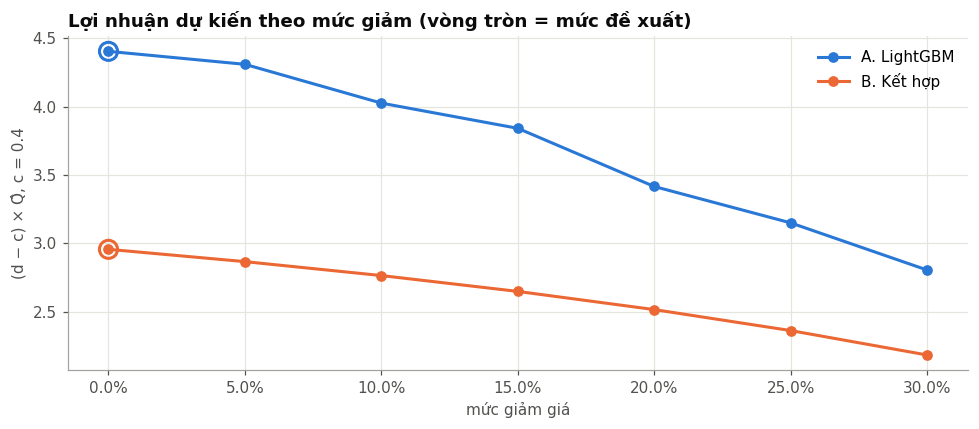

In [9]:
cand = np.where(te.top20.values & (ALLOWED.sum(1) >= 5))[0]
i = int(cand[np.argmax(base[cand])]) if len(cand) else int(np.argmax(base))
row = te.iloc[i]
ex = pd.DataFrame({"mức giảm": [f"{int(round((1 - d) * 100))}%" for d in GRID], "d": GRID,
                   "được phép": ALLOWED[i],
                   "Q̂ (A)": QA[i], "Q̂ (B)": QB[i]})
for tag, Q in [("A", QA), ("B", QB)]:
    ex[f"R ({tag})"] = GRID * Q[i]
    ex[f"π ({tag}), c={MAIN_COST}"] = (GRID - MAIN_COST) * Q[i]
ex.to_csv(OUT_DIR / "tables" / "table_example_recommendation.csv", index=False)
print(f"Sản phẩm {row['product_id']} tại cửa hàng {row['store_id']}, ngày {pd.Timestamp(row['dt']).date()}, "
      f"nhóm '{row['el_group']}', E = {row['E']:.2f}, discount thực tế = {row['discount']:.2f}")
display(ex.style.format({c: "{:.3f}" for c in ex.columns if c not in ("mức giảm", "được phép")}))

fig, ax = plt.subplots(figsize=(9, 4))
for tag, Q, col in [("A. LightGBM", QA, C1), ("B. Kết hợp", QB, C2)]:
    pi = (GRID - MAIN_COST) * Q[i]
    pi_masked = np.where(ALLOWED[i], pi, np.nan)
    ax.plot(1 - GRID, pi_masked, marker="o", color=col, label=tag)
    j = np.nanargmax(pi_masked)
    ax.scatter([1 - GRID[j]], [pi_masked[j]], s=140, facecolor="none", edgecolor=col, linewidth=2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Lợi nhuận dự kiến theo mức giảm (vòng tròn = mức đề xuất)"); ax.set_xlabel("mức giảm giá")
ax.set_ylabel(f"(d − c) × Q̂, c = {MAIN_COST}"); ax.legend()
save(fig, "opt_example_profit_curve")

## 6. Lưu kết quả cho notebook 05 và demo

In [10]:
rec = te[["series_id", "store_id", "product_id", "first_category_id", "dt", "discount", "el_group", "E", "top20"]].copy()
rec["store_id"] = rec.store_id.astype(int); rec["product_id"] = rec.product_id.astype(int)
rec["first_category_id"] = rec.first_category_id.astype(int)
rec["q_base"] = base
for k, d in enumerate(GRID):
    rec[f"qA_{d:.2f}"] = QA[:, k].astype("float32")
    rec[f"qB_{d:.2f}"] = QB[:, k].astype("float32")
    rec[f"allowed_{d:.2f}"] = ALLOWED[:, k]
for c in COSTS:
    rec[f"dA_c{c}"] = D_OPT[("A. LightGBM", c)]
    rec[f"dB_c{c}"] = D_OPT[("B. Kết hợp", c)]
rec.to_parquet(OUT_DIR / "data" / "recommendations.parquet", index=False)
json.dump({"grid": GRID.tolist(), "costs": COSTS, "main_cost": MAIN_COST, "extrap_steps": EXTRAP_STEPS,
           "E_overall": E_OVERALL, "E_clip": E_CLIP},
          open(OUT_DIR / "data" / "pricing_config.json", "w"), indent=2)

main = res[res.c == MAIN_COST].set_index("cách")
summary = pd.DataFrame([
    ("Δ lợi nhuận vs giá lịch sử (c = 0,4)", f"A: {pct(main.loc['A. LightGBM', 'Δπ vs lịch sử'])} | B: {pct(main.loc['B. Kết hợp', 'Δπ vs lịch sử'])}"),
    ("Δ doanh thu vs giá lịch sử (c = 0,4)", f"A: {pct(main.loc['A. LightGBM', 'ΔR vs lịch sử'])} | B: {pct(main.loc['B. Kết hợp', 'ΔR vs lịch sử'])}"),
    ("Tỷ lệ ngày có giảm giá", f"lịch sử {main.iloc[0]['ngày có giảm (lịch sử)']:.1%} | A {main.loc['A. LightGBM', 'ngày có giảm (tối ưu)']:.1%} | B {main.loc['B. Kết hợp', 'ngày có giảm (tối ưu)']:.1%}"),
    ("Khoảng Δ lợi nhuận qua 3 mức giá vốn", f"A: {pct(res[res['cách'] == 'A. LightGBM']['Δπ vs lịch sử'].min())} → {pct(res[res['cách'] == 'A. LightGBM']['Δπ vs lịch sử'].max())} | "
                                           f"B: {pct(res[res['cách'] == 'B. Kết hợp']['Δπ vs lịch sử'].min())} → {pct(res[res['cách'] == 'B. Kết hợp']['Δπ vs lịch sử'].max())}"),
    ("Mục tiêu doanh thu chọn mức giảm sâu nhất", f"A: {rev_bound['A. LightGBM']:.1%} | B: {rev_bound['B. Kết hợp']:.1%} số dòng"),
], columns=["Chỉ tiêu", "Kết quả"])
summary.to_csv(OUT_DIR / "tables" / "opt_summary.csv", index=False)
summary

,Chỉ tiêu,Kết quả
0,"Δ lợi nhuận vs giá lịch sử (c = 0,4)",A: +10.0% | B: +16.4%
1,"Δ doanh thu vs giá lịch sử (c = 0,4)",A: +5.4% | B: +16.9%
2,Tỷ lệ ngày có giảm giá,lịch sử 51.8% | A 77.0% | B 49.9%
3,Khoảng Δ lợi nhuận qua 3 mức giá vốn,A: +8.5% → +13.0% | B: +16.4% → +17.1%
4,Mục tiêu doanh thu chọn mức giảm sâu nhất,A: 29.8% | B: 71.8% số dòng
